In [1]:
import sys
sys.path.append('..') 

from utils.emb_labels import align_embeddings_with_labels, read_embeddings_dataset

[/bigdata/md5_s6cfa268729ee2148ee90bbb3acd/NewProject/embeddings_sibiu/embeddings_lstm_sibiu_0.txt] Dropping first 0 and last 1 instances to align data.
Running UMAP on 43847 samples... (this may take a minute)


/bigdata/md5_s6cfa268729ee2148ee90bbb3acd/miniconda3/envs/new_project/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


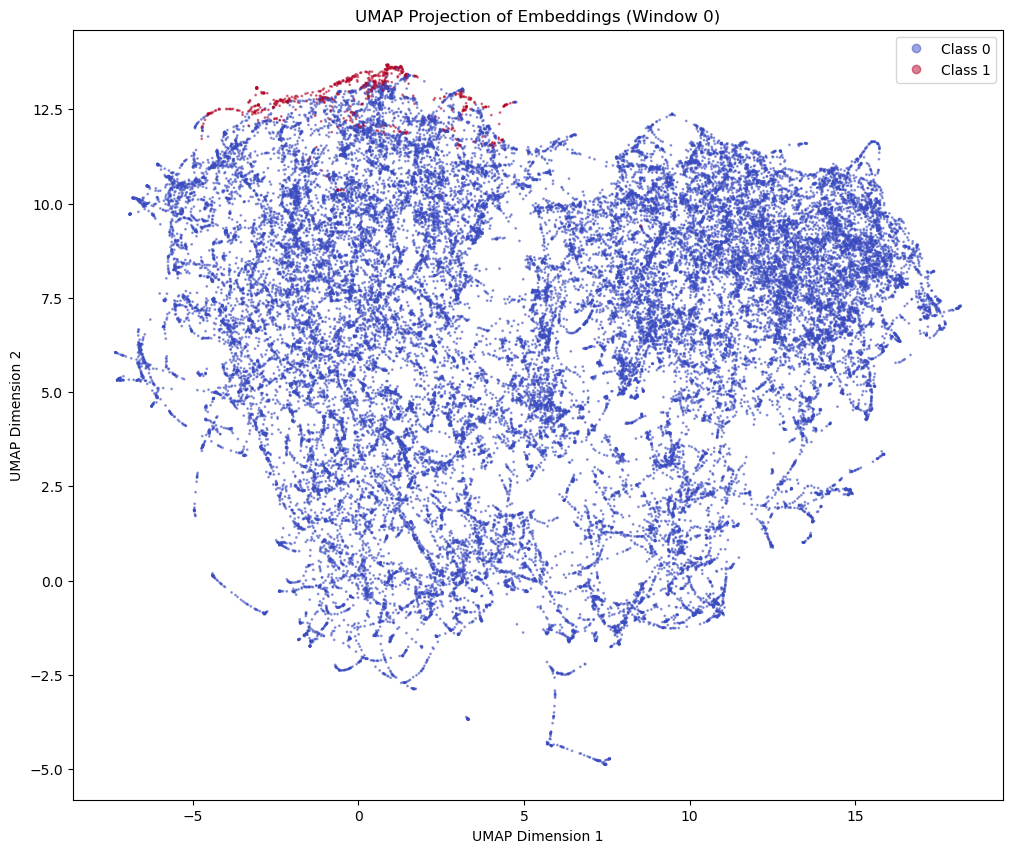

In [4]:
import umap
import matplotlib.pyplot as plt
import pandas as pd

embedding_path = r"/bigdata/md5_s6cfa268729ee2148ee90bbb3acd/NewProject/embeddings_sibiu/embeddings_lstm_sibiu_0.txt"
labels_path = r"/bigdata/md5_s6cfa268729ee2148ee90bbb3acd/NewProject/labels_msl/msl_classes_1000.csv"

# aligned_df is a DataFrame: [date, label, emb_0, emb_1, ... emb_255]
aligned_df = align_embeddings_with_labels(embedding_path=embedding_path, labels_path=labels_path)

features = aligned_df.drop(columns=['date', 'label']).values
labels = aligned_df['label'].values

print(f"Running UMAP on {features.shape[0]} samples... (this may take a minute)")
reducer = umap.UMAP(
    n_components=2, 
    metric='cosine', 
    n_neighbors=15, 
    min_dist=0.1,
    random_state=42,
    low_memory=False,
    
)

embedding_2d = reducer.fit_transform(features)

# 4. Create the visualization
plt.figure(figsize=(12, 10))

scatter = plt.scatter(
    embedding_2d[:, 0], 
    embedding_2d[:, 1], 
    c=labels,           
    cmap='coolwarm',    
    s=1,                
    alpha=0.5           
)

plt.title("UMAP Projection of Embeddings (Window 0)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")

plt.legend(handles=scatter.legend_elements()[0], labels=['Class 0', 'Class 1'])
plt.show()